# 08. Обучение классификатора покрытия

Серое — ядро, белая окантовка — покрытие.
Классы: `coated` и `insufficient_coating` — тонкая, прерывистая или отсутствующая окантовка.
Спорные и неразмеченные кропы исключаются из обучения.
Визуальная разметка предварительная, без проверки материаловедом. Оценивается видимая окантовка.


In [1]:
from pathlib import Path
import copy
import hashlib
import json
import math
import random
import time

import cv2
import numpy as np
import pandas as pd
from PIL import Image, ImageEnhance, ImageOps
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

ROOT = Path.cwd().resolve()
if ROOT.name == 'research':
    ROOT = ROOT.parent
OUT = ROOT / 'models/recall90_20261024/coating'
OUT.mkdir(parents=True, exist_ok=True)
MANIFEST = ROOT / 'models/two_stage_20261024/coating/gt_crops.csv'
LABELS = OUT / 'visual_labels.csv'
LABEL_ORIGIN = 'provisional_assistant_visual'
CLASSES = ('coated', 'insufficient_coating')
RUSSIAN = {'coated': 'покрыта', 'insufficient_coating': 'не покрыта'}
SEED, SIZE, PADDING, BATCH = 42, 320, 0.10, 32
HEAD_EPOCHS, FINETUNE_EPOCHS, PATIENCE = 5, 15, 5
TRAIN_MINUTES, FALLBACK_MINUTES = 54.0, 3.0
RUN_TRAINING = True  # Три профиля, каждый: 5+15 эпох, максимум 54+3 минуты.
TARGET_ACCEPTED_ACCURACY, MIN_COVERAGE = 0.90, 0.25
DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
PROFILES = {'raw': dict(preprocessing='raw', photometric=False),
            'mild_aug': dict(preprocessing='raw', photometric=True),
            'clahe': dict(preprocessing='clahe', photometric=False)}


def reset_seed():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


reset_seed()

## Данные

Кропы по размеченным bbox с 10% контекста.
Train — D03/D04, val — D01/D02, test — D05. Кропы одного кадра остаются в одной выборке.
У вариантов одинаковые начальные веса, seed и бюджет. Выбор по val; D05 использовалась раньше.


In [2]:
manifest = pd.read_csv(MANIFEST, keep_default_na=False)
if not LABELS.exists():
    raise FileNotFoundError(f'Сначала требуется таблица визуальной разметки: {LABELS}')
labels = pd.read_csv(LABELS, dtype=str, keep_default_na=False)
if labels.crop_id.duplicated().any():
    raise ValueError('Повтор crop_id в таблице разметки.')
table = manifest.merge(labels[['crop_id', 'label', 'reviewer', 'note']], on='crop_id',
                       how='left', validate='one_to_one')
table[['label', 'reviewer', 'note']] = table[['label', 'reviewer', 'note']].fillna('')
table['label'] = table.label.str.strip()
if not set(table.label).issubset({'', 'uncertain', *CLASSES}):
    raise ValueError('Допустимы coated / insufficient_coating / uncertain / пустая метка.')
confirmed = table.loc[table.label.isin(CLASSES)].copy()
group_splits = confirmed.groupby('group').split.nunique()
if (group_splits > 1).any():
    raise ValueError('Исходная группа попала в несколько выборок.')
COUNTS = pd.crosstab(confirmed.split, confirmed.label).reindex(
    index=['train', 'val', 'test'], columns=CLASSES, fill_value=0).fillna(0).astype(int)
display(COUNTS)
print('Происхождение меток:', LABEL_ORIGIN, '| reviewers:', sorted(set(confirmed.reviewer)))
print('Спорные:', int((table.label == 'uncertain').sum()), '| Без метки:', int((table.label == '').sum()))
CAN_TRAIN = bool((COUNTS.loc[['train', 'val']] > 0).all().all())
LABELS_SHA = hashlib.sha256(LABELS.read_bytes()).hexdigest()
MANIFEST_SHA = hashlib.sha256(MANIFEST.read_bytes()).hexdigest()
DATA_KEY = hashlib.sha256((LABELS_SHA + MANIFEST_SHA).encode()).hexdigest()

label,coated,insufficient_coating
split,,
train,77,45
val,11,33
test,3,20


Происхождение меток: provisional_assistant_visual | reviewers: ['assistant_visual_20261024']
Спорные: 105 | Без метки: 973


## Подготовка изображений

Вход 320 px с сохранением пропорций. В train — отражения и повороты на 90°.
`raw` — исходные интенсивности; `mild_aug` — яркость/контраст ±10% только в train;
`clahe` — локальный контраст при обучении и применении. CLAHE может усиливать шум.


In [3]:
def letterbox(image, size):
    image = image.convert('RGB')
    array = np.asarray(image)
    border = np.concatenate((array[0], array[-1], array[:, 0], array[:, -1]))
    color = tuple(np.median(border, axis=0).astype(int))
    return ImageOps.pad(image, (size, size), method=Image.Resampling.BICUBIC, color=color)


def prepare_crop(image, preprocessing='raw'):
    image = image.convert('RGB')
    if preprocessing == 'clahe':
        gray = cv2.cvtColor(np.asarray(image), cv2.COLOR_RGB2GRAY)
        gray = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)
        image = Image.fromarray(gray).convert('RGB')
    return image


TENSOR = transforms.Compose([transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])


def classification_scores(predictions):
    matrix = np.zeros((2, 2), dtype=int)
    for target, predicted in predictions[['target', 'predicted']].itertuples(index=False, name=None):
        if target in (0, 1):
            matrix[int(target), int(predicted)] += 1
    tp, support = np.diag(matrix), matrix.sum(1)
    precision = np.divide(tp, matrix.sum(0), out=np.zeros(2, dtype=float), where=matrix.sum(0) > 0)
    recall = np.divide(tp, support, out=np.full(2, np.nan), where=support > 0)
    f1 = np.divide(2 * tp, support + matrix.sum(0), out=np.zeros(2, dtype=float),
                   where=support + matrix.sum(0) > 0)
    scores = dict(count=int(matrix.sum()), accuracy=float(tp.sum() / max(matrix.sum(), 1)),
        balanced_accuracy=float(np.nanmean(recall)) if support.any() else None,
        macro_f1=float(f1.mean()), support_coated=int(support[0]), support_insufficient=int(support[1]))
    return scores, matrix, precision, recall


class CropDataset(Dataset):
    def __init__(self, rows, profile='raw', train=False, size=SIZE):
        self.rows = rows.reset_index(drop=True)
        self.profile, self.train, self.size = profile, train, size

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows.iloc[index]
        image = Image.open(ROOT / row['crop']).convert('RGB')
        profile = PROFILES[self.profile]
        image = prepare_crop(image, profile['preprocessing'])
        if self.train:
            image = image.rotate(random.choice((0, 90, 180, 270)), expand=True)
            if random.random() < 0.5:
                image = ImageOps.mirror(image)
            if random.random() < 0.5:
                image = ImageOps.flip(image)
            if profile['photometric']:
                image = ImageEnhance.Brightness(image).enhance(random.uniform(0.9, 1.1))
                image = ImageEnhance.Contrast(image).enhance(random.uniform(0.9, 1.1))
        return TENSOR(letterbox(image, self.size)), CLASSES.index(row.label), row.crop_id


def make_loaders(profile, size):
    return {split: DataLoader(CropDataset(confirmed.loc[confirmed.split == split], profile,
            train=split == 'train', size=size), batch_size=BATCH,
            shuffle=split == 'train', num_workers=0,
            generator=torch.Generator().manual_seed(SEED)) for split in ('train', 'val', 'test')}


def new_classifier(pretrained=False):
    cached = Path.home() / '.cache/torch/hub/checkpoints/resnet18-f37072fd.pth'
    if pretrained and cached.is_file():
        model = models.resnet18(weights=None)
        model.load_state_dict(torch.load(cached, map_location='cpu', weights_only=True))
    else:
        torch.hub.set_dir(str(OUT / 'pretrained'))
        model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
    model.fc = nn.Linear(model.fc.in_features, len(CLASSES))
    return model.to(DEVICE)


@torch.inference_mode()
def predict_loader(model, loader):
    model.eval()
    rows = []
    for images, targets, ids in loader:
        probabilities = model(images.to(DEVICE)).softmax(1).cpu().numpy()
        for crop_id, target, prob in zip(ids, targets.tolist(), probabilities):
            rows.append(dict(crop_id=crop_id, target=target, predicted=int(prob.argmax()),
                confidence=float(prob.max()), p_coated=float(prob[0]), p_insufficient=float(prob[1])))
    return pd.DataFrame(rows, columns=['crop_id', 'target', 'predicted', 'confidence',
                                       'p_coated', 'p_insufficient'])

### Сравнение с CLAHE

Исходный кроп и результат CLAHE для трёх частиц из val: покрытой, недостаточно покрытой и спорной.
Метки сохраняются.


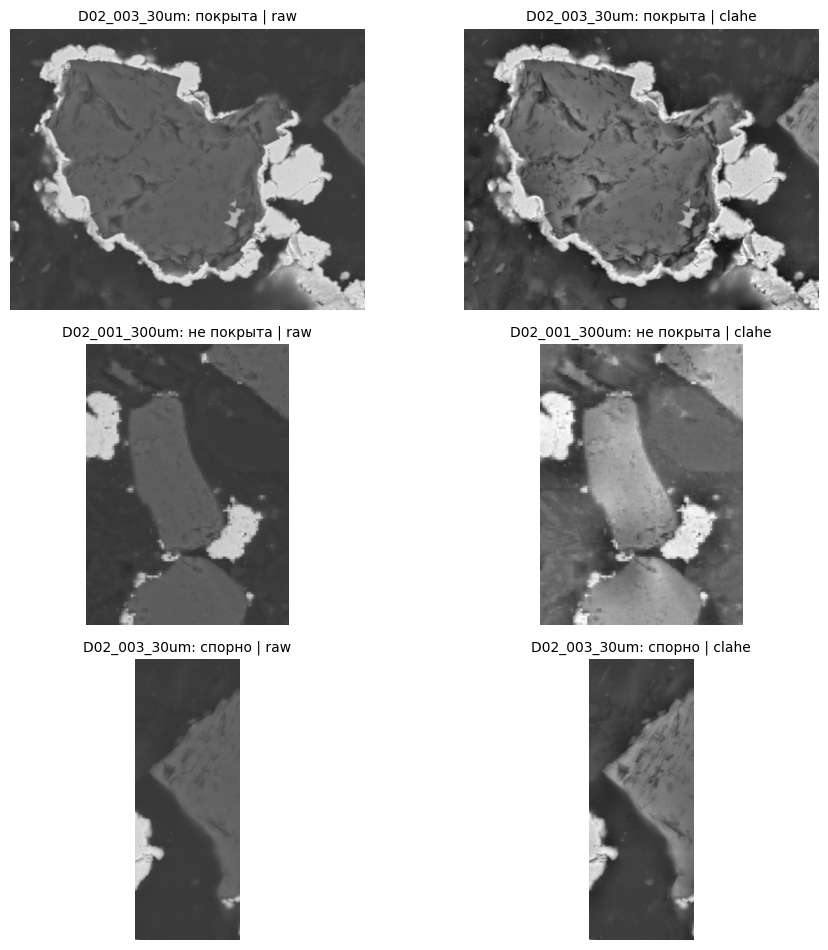

In [4]:
comparison_examples = []
for label in (*CLASSES, 'uncertain'):
    choices = table.loc[(table.split == 'val') & (table.label == label)].copy()
    if len(choices):
        choices['area'] = (choices.x2 - choices.x1) * (choices.y2 - choices.y1)
        comparison_examples.append(choices.sort_values('area', ascending=False).iloc[0])
if comparison_examples:
    fig, axes = plt.subplots(len(comparison_examples), 2, figsize=(10, 3.2 * len(comparison_examples)), squeeze=False)
    for axes_row, row in zip(axes, comparison_examples):
        image = Image.open(ROOT / row['crop']).convert('RGB')
        label_ru = RUSSIAN.get(row.label, 'спорно')
        for ax, preprocessing in zip(axes_row, ('raw', 'clahe')):
            ax.imshow(prepare_crop(image, preprocessing))
            ax.set_title(f'{row.image_id}: {label_ru} | {preprocessing}', fontsize=10)
            ax.axis('off')
    plt.tight_layout()
    plt.show()

## Обучение

ResNet18 с ImageNet-весами: 5 эпох выходного слоя, до 15 эпох всей сети, early stopping — 5.
Выбор по val balanced accuracy, при равенстве — macro F1. Веса классов рассчитываются по train.
Лимит — 54 минуты, затем при необходимости до 3 минут с входом 224 px и обучением выходного слоя.


In [4]:
def train_profile(profile, size=SIZE, minutes=TRAIN_MINUTES, head_epochs=HEAD_EPOCHS,
                  finetune_epochs=FINETUNE_EPOCHS, initial=None, suffix=''):
    reset_seed()
    directory = OUT / f'resnet18_{profile}{suffix}'
    directory.mkdir(exist_ok=True)
    best_path = directory / 'best.pt'
    signature = dict(profile=profile, size=size, head_epochs=head_epochs,
                     finetune_epochs=finetune_epochs, seed=SEED, data_key=DATA_KEY)
    if best_path.exists():
        saved = torch.load(best_path, map_location='cpu', weights_only=True)
        if saved.get('signature') != signature:
            raise FileExistsError(f'Другая серия уже сохранена: {directory}. Измените OUT.')
        print('Сохранённый профиль:', profile, suffix)
        return best_path, saved['run_status']
    loaders = make_loaders(profile, size)
    model = new_classifier(pretrained=initial is None)
    if initial is not None:
        model.load_state_dict(torch.load(initial, map_location='cpu', weights_only=True)['state_dict'])
    train_counts = COUNTS.loc['train'].to_numpy(dtype=float)
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(train_counts.sum() / (2 * train_counts),
                                                        dtype=torch.float32, device=DEVICE))
    best_rank, best_state, history = (-1.0, -1.0), None, []
    begin, timed_out = time.perf_counter(), False
    limit = min(float(minutes), 54.0) * 60
    for stage, epochs, lr in [('head', head_epochs, 1e-3), ('finetune', finetune_epochs, 1e-4)]:
        for parameter in model.parameters():
            parameter.requires_grad = stage == 'finetune'
        for parameter in model.fc.parameters():
            parameter.requires_grad = True
        optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                                      lr=lr, weight_decay=1e-4)
        stale = 0
        for epoch in range(epochs):
            model.train()
            if stage == 'head':
                model.eval()
                model.fc.train()
            total_loss, seen = 0.0, 0
            for images, targets, _ in loaders['train']:
                if time.perf_counter() - begin >= limit:
                    timed_out = True
                    break
                optimizer.zero_grad(set_to_none=True)
                images, targets = images.to(DEVICE), targets.to(DEVICE)
                loss = criterion(model(images), targets)
                loss.backward()
                optimizer.step()
                total_loss += float(loss.detach()) * len(images)
                seen += len(images)
            if timed_out or time.perf_counter() - begin >= limit:
                timed_out = True
                break
            val_predictions = predict_loader(model, loaders['val'])
            metrics = classification_scores(val_predictions)[0]
            rank = (metrics['balanced_accuracy'], metrics['macro_f1'])
            history.append(dict(stage=stage, epoch=epoch + 1,
                                train_loss=total_loss / max(seen, 1), **metrics))
            print(profile, stage, epoch + 1, 'val BA/F1:', round(rank[0], 3), round(rank[1], 3))
            if rank > best_rank:
                best_rank, stale = rank, 0
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            else:
                stale += 1
            if stale >= PATIENCE:
                break
        if timed_out:
            break
        if best_state is not None:
            model.load_state_dict(best_state)
    run_status = dict(status='time_limited' if timed_out else 'completed_or_early_stopped',
        elapsed_seconds=time.perf_counter() - begin, epochs_completed=len(history),
        minutes=float(minutes), reason='wall_clock_budget' if timed_out else None)
    current_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    state = best_state if best_state is not None else current_state
    checkpoint = dict(state_dict=state, architecture='resnet18', classes=list(CLASSES),
        preprocessing=PROFILES[profile]['preprocessing'], profile=profile, size=size,
        padding=PADDING, seed=SEED, imagenet_weights='IMAGENET1K_V1', label_origin=LABEL_ORIGIN,
        reviewers=sorted(set(confirmed.reviewer)), labels_sha256=LABELS_SHA,
        manifest_sha256=MANIFEST_SHA, signature=signature, run_status=run_status,
        val_balanced_accuracy=best_rank[0], val_macro_f1=best_rank[1])
    torch.save(checkpoint, best_path)
    if timed_out:
        torch.save({**checkpoint, 'state_dict': current_state}, directory / 'last.pt')
    pd.DataFrame(history).to_csv(directory / 'history.csv', index=False)
    del model, optimizer
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return best_path, run_status


candidates = []
if RUN_TRAINING and CAN_TRAIN:
    for profile in PROFILES:
        best_path, status = train_profile(profile)
        candidates.append(best_path)
        if status['status'] == 'time_limited':
            fallback, fallback_status = train_profile(profile, size=224, minutes=FALLBACK_MINUTES,
                head_epochs=5, finetune_epochs=0, initial=best_path, suffix='_fallback224')
            candidates.append(fallback)
elif RUN_TRAINING:
    print('Нужны оба размеченных класса в train и val; обучение не выполнено.')
else:
    candidates = sorted(OUT.glob('resnet18_*/best.pt'))
    print('Обучение выключено; доступны сохранённые профили:', len(candidates))

raw head 1 val BA/F1: 0.621 0.429


raw head 2 val BA/F1: 0.576 0.581


raw head 3 val BA/F1: 0.53 0.504


raw head 4 val BA/F1: 0.561 0.558


raw head 5 val BA/F1: 0.561 0.558


...

clahe finetune 11 val BA/F1: 0.909 0.843


clahe finetune 12 val BA/F1: 0.909 0.843


clahe finetune 13 val BA/F1: 0.924 0.866


clahe finetune 14 val BA/F1: 0.924 0.866


clahe finetune 15 val BA/F1: 0.924 0.866


## Выбор модели и порога

Сравнение на одинаковых val-кропах. Порог уверенности: точность принятых ответов ≥90%, доля принятых ≥25%.
Если условия не выполнены, все ответы помечаются для проверки. Бинарный класс выводится всегда.
Уверенность softmax не гарантирует точность.


In [5]:
comparison, val_tables = [], {}
for path in candidates:
    checkpoint = torch.load(path, map_location='cpu', weights_only=True)
    if checkpoint['signature']['data_key'] != DATA_KEY:
        continue
    model = new_classifier(pretrained=False)
    model.load_state_dict(checkpoint['state_dict'])
    loader = make_loaders(checkpoint['profile'], checkpoint['size'])['val']
    prediction = predict_loader(model, loader)
    metrics = classification_scores(prediction)[0]
    prediction.to_csv(path.parent / 'val_predictions.csv', index=False)
    comparison.append(dict(profile=path.parent.name, weights=path.relative_to(ROOT).as_posix(),
        size=checkpoint['size'], status=checkpoint['run_status']['status'], **metrics))
    val_tables[str(path)] = prediction
    del model
comparison = pd.DataFrame(comparison)
selected = None
if len(comparison):
    comparison = comparison.sort_values(['balanced_accuracy', 'macro_f1'], ascending=False)
    comparison.to_csv(OUT / 'comparison_val.csv', index=False)
    display(comparison.round(4))
    chosen = ROOT / comparison.iloc[0].weights
    checkpoint = torch.load(chosen, map_location='cpu', weights_only=True)
    validation = val_tables[str(chosen)]
    curve = []
    for threshold in np.linspace(0.5, 0.99, 50):
        accepted = validation.loc[validation.confidence >= threshold]
        curve.append(dict(threshold=float(threshold), accepted=len(accepted),
            coverage=len(accepted) / max(len(validation), 1),
            accuracy=float((accepted.target == accepted.predicted).mean()) if len(accepted) else np.nan))
    curve = pd.DataFrame(curve)
    eligible = curve.loc[(curve.accuracy >= TARGET_ACCEPTED_ACCURACY) & (curve.coverage >= MIN_COVERAGE)]
    threshold = float(eligible.sort_values(['coverage', 'threshold'], ascending=[False, True]).iloc[0].threshold) if len(eligible) else 1.01
    curve.to_csv(OUT / 'val_risk_coverage.csv', index=False)
    selected = dict(architecture='resnet18', weights=chosen.relative_to(ROOT).as_posix(),
        weight_sha256=hashlib.sha256(chosen.read_bytes()).hexdigest(), classes=list(CLASSES),
        russian_labels=RUSSIAN, preprocessing=checkpoint['preprocessing'], profile=checkpoint['profile'],
        size=checkpoint['size'], padding=checkpoint['padding'], confidence_threshold=threshold,
        label_origin=LABEL_ORIGIN, labels=LABELS.relative_to(ROOT).as_posix(), labels_sha256=LABELS_SHA,
        manifest=MANIFEST.relative_to(ROOT).as_posix(), manifest_sha256=MANIFEST_SHA,
        seed=SEED, selected_on='val', selection_metric='balanced_accuracy_then_macro_f1',
        val_metrics=classification_scores(validation)[0], run_status=checkpoint['run_status'])
    (OUT / 'selected_pipeline.json').write_text(json.dumps(selected, indent=2, ensure_ascii=False), encoding='utf-8')
    print('Выбран:', selected['profile'], '| порог сомнения:', threshold)

,profile,weights,size,status,count,accuracy,balanced_accuracy,macro_f1,support_coated,support_insufficient
1,resnet18_mild_aug,models/recall90_20261024/coating/resnet18_mild...,320,completed_or_early_stopped,44,0.9318,0.9242,0.9117,11,33
2,resnet18_clahe,models/recall90_20261024/coating/resnet18_clah...,320,completed_or_early_stopped,44,0.8864,0.9242,0.8664,11,33
0,resnet18_raw,models/recall90_20261024/coating/resnet18_raw/...,320,completed_or_early_stopped,44,0.8864,0.8939,0.8603,11,33


Выбран: mild_aug | порог сомнения: 0.5


## Проверка на test

Оценка выбранной на val модели по предварительным меткам.
Test небольшой и уже использовался; для независимой оценки нужны новые образцы.


In [6]:
if selected is not None:
    checkpoint = torch.load(ROOT / selected['weights'], map_location='cpu', weights_only=True)
    model = new_classifier(pretrained=False)
    model.load_state_dict(checkpoint['state_dict'])
    test = predict_loader(model, make_loaders(selected['profile'], selected['size'])['test'])
    test['uncertain_flag'] = test.confidence < selected['confidence_threshold']
    test['status'] = np.where(test.uncertain_flag, 'needs_review', 'automatic_hypothesis')
    test['prediction_ru'] = test.predicted.map(lambda i: RUSSIAN[CLASSES[i]])
    test = test.merge(confirmed[['crop_id', 'image_id', 'group', 'reviewer']], on='crop_id')
    test.to_csv(OUT / 'test_predictions.csv', index=False)
    scores, matrix, precision, recall = classification_scores(test)
    accepted = test.loc[~test.uncertain_flag]
    scores.update(coverage=len(accepted) / max(len(test), 1),
        accepted_accuracy=float((accepted.target == accepted.predicted).mean()) if len(accepted) else None,
        label_origin=LABEL_ORIGIN, independent_test=False)
    (OUT / 'test_metrics.json').write_text(json.dumps(scores, indent=2, ensure_ascii=False), encoding='utf-8')
    display(pd.DataFrame([scores]).round(4))
    display(pd.DataFrame(matrix, index=['GT: покрыта', 'GT: не покрыта'], columns=['модель: покрыта', 'модель: не покрыта']))
    display(pd.DataFrame({'класс': [RUSSIAN[c] for c in CLASSES], 'precision': precision, 'recall': recall}).round(4))
    if not (COUNTS.loc['test'] > 0).all():
        print('В test нет обоих классов; оценка неполная.')
    by_frame = test.assign(correct=test.target == test.predicted).groupby('image_id').agg(
        count=('crop_id', 'size'), accuracy=('correct', 'mean'), uncertain=('uncertain_flag', 'mean'))
    display(by_frame.round(3))
    del model

,count,accuracy,balanced_accuracy,macro_f1,support_coated,support_insufficient,coverage,accepted_accuracy,label_origin,independent_test
0,23,1.0,1.0,1.0,3,20,1.0,1.0,provisional_assistant_visual,False


,модель: покрыта,модель: не покрыта
GT: покрыта,3,0
GT: не покрыта,0,20


,класс,precision,recall
0,покрыта,1.0,1.0
1,не покрыта,1.0,1.0


,count,accuracy,uncertain
image_id,,,
D05_001_400um,20,1.0,0.0
D05_003_40um,3,1.0,0.0


## Просмотр предсказаний

Метка, предсказанный класс и уверенность на test-кропах.
Красная подпись — ошибка, `?` — низкая уверенность. Параметры по test не подбираются.


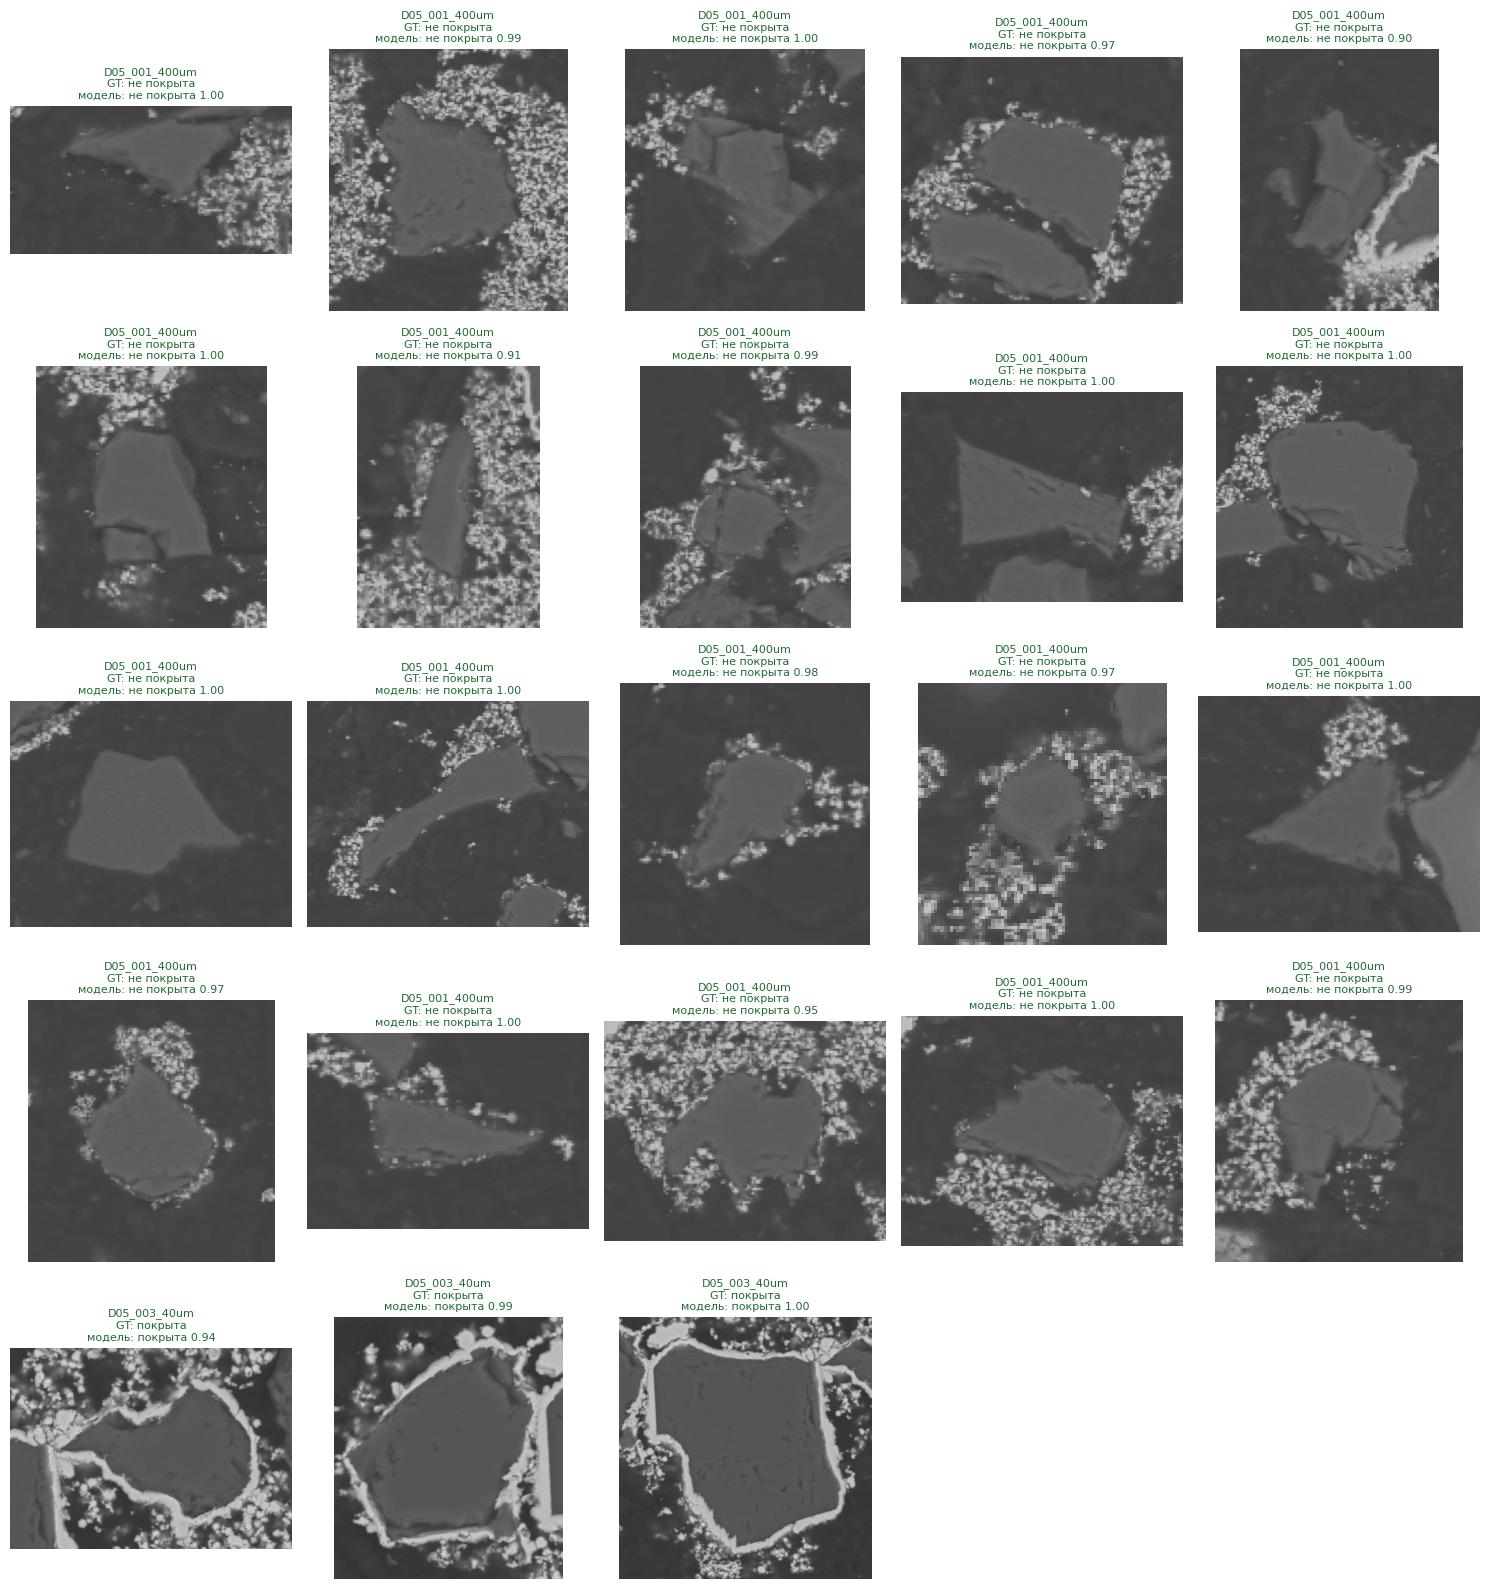

In [7]:
if selected is not None:
    gallery = test.merge(confirmed[['crop_id', 'crop', 'label']], on='crop_id').head(30)
    if len(gallery):
        fig, axes = plt.subplots(math.ceil(len(gallery) / 5), 5,
            figsize=(15, 3.2 * math.ceil(len(gallery) / 5)), squeeze=False)
        for ax, row in zip(axes.flat, gallery.itertuples(index=False)):
            ax.imshow(Image.open(ROOT / row.crop))
            correct = row.target == row.predicted
            flag = ' ?' if row.uncertain_flag else ''
            ax.set_title(f'{row.image_id}\nGT: {RUSSIAN[row.label]}\nмодель: {row.prediction_ru} {row.confidence:.2f}{flag}',
                         fontsize=8, color='#216a34' if correct else '#b22222')
            ax.axis('off')
        for ax in list(axes.flat)[len(gallery):]:
            ax.axis('off')
        plt.tight_layout()
        fig.savefig(OUT / 'test_gallery.jpg', dpi=160, bbox_inches='tight')
        plt.show()

## Источники

[PyTorch](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html) — перенос обучения.
[OpenCV](https://docs.opencv.org/4.x/d5/daf/tutorial_py_histogram_equalization.html) — CLAHE.
[Selective classification](https://arxiv.org/abs/1705.08500) — порог уверенности и доля принятых ответов.
